# Phase 6: crop, resize, cut into squares and label

## 6.1 Crop and resize (the same rule the app will use)

For every photo:
1. **Crop:** keep the bottom 5/8 (the top 3/8 is mostly sky and buildings).
2. **Resize** to 640 × 400.
3. **Move the boxes** the same way: subtract the crop offset from y, multiply by the resize factors, clip what sticks out, drop boxes that are entirely cut off.

Cutting into squares and labelling them is 6.2 (not here).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from PIL import Image

sys.path.insert(0, str(Path.cwd().parents[1]))
from ml import config

src = config.PROCESSED / "04_clean"
images, boxes = pd.read_csv(src / "images_clean.csv"), pd.read_csv(src / "boxes_clean.csv")
CLASSES = ["D00", "D10", "D20", "D40"]
COLORS = ["#3b82f6", "#a855f7", "#f59e0b", "#ef4444"]
NAMES = {"D00": "D00 · Longitudinal crack", "D10": "D10 · Transverse crack", "D20": "D20 · Alligator crack", "D40": "D40 · Pothole"}
LEGEND = [plt.Rectangle((0, 0), 1, 1, color=c, label=NAMES[k]) for k, c in zip(CLASSES, COLORS)]


def crop_top(height):
    """The row where the crop starts: we keep the bottom 5/8 of the photo."""
    return height - round(height * config.CROP_KEEP)


def crop_resize(img):
    """Photo -> bottom 5/8 -> 640 x 400. THE APP MUST DO EXACTLY THIS."""
    w, h = img.size
    return img.crop((0, crop_top(h), w, h)).resize((config.IMG_W, config.IMG_H), Image.BILINEAR)


def draw(ax, boxes_df, cols):
    xmin, ymin, xmax, ymax = cols
    for r in boxes_df.itertuples():
        c = COLORS[CLASSES.index(r.cls)]
        x0, y0, x1, y1 = getattr(r, xmin), getattr(r, ymin), getattr(r, xmax), getattr(r, ymax)
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, facecolor=c, alpha=0.25))
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=c, linewidth=2))

### 1. One photo, step by step

Japan_012660: 600 x 600. Keep rows 225 to 600, so the crop is 600 x 375 (cut off the top 225 px).


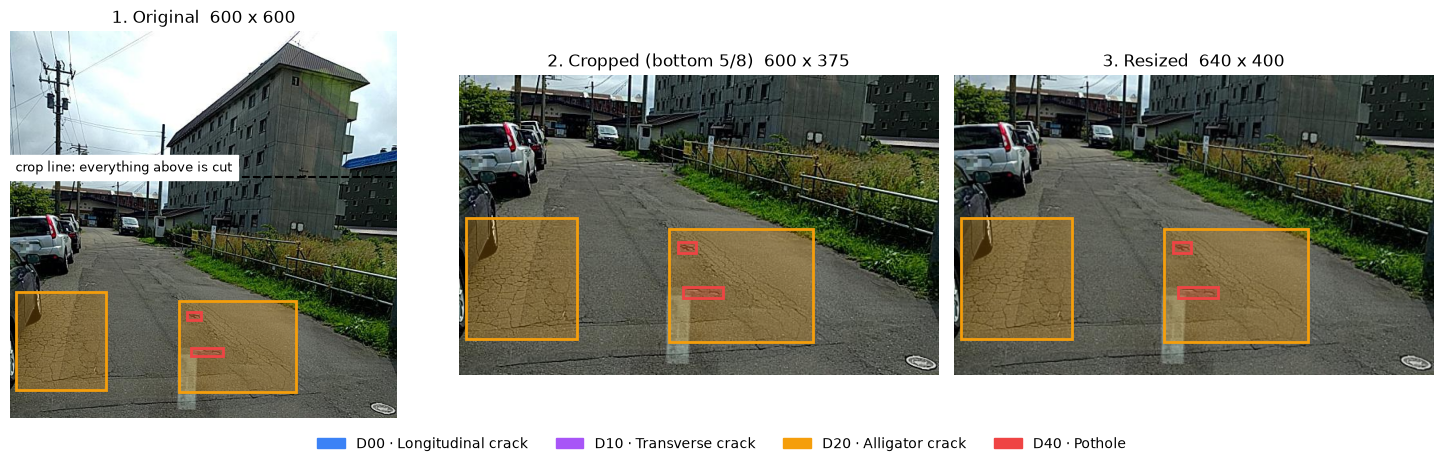

In [2]:
ID = "Japan_012660"
info = images.set_index("image_id").loc[ID]
img = Image.open(config.RAW / info["path"]).convert("RGB")
W, H = img.size
top = crop_top(H)
one = boxes[boxes.image_id == ID]
print(f"{ID}: {W} x {H}. Keep rows {top} to {H}, so the crop is {W} x {H - top} (cut off the top {top} px).")

cropped = img.crop((0, top, W, H))
resized = crop_resize(img)
sx, sy = config.IMG_W / W, config.IMG_H / (H - top)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
axes[0].imshow(img)
axes[0].axhline(top, color="black", linestyle="--")
axes[0].text(8, top - 8, "crop line: everything above is cut", fontsize=9, backgroundcolor="white")
axes[0].set_title(f"1. Original  {W} x {H}")
draw(axes[0], one, ("xmin", "ymin", "xmax", "ymax"))
axes[1].imshow(cropped)
axes[1].set_title(f"2. Cropped (bottom 5/8)  {W} x {H - top}")
draw(axes[1], one.assign(ymin=one.ymin - top, ymax=one.ymax - top), ("xmin", "ymin", "xmax", "ymax"))
axes[2].imshow(resized)
axes[2].set_title(f"3. Resized  {config.IMG_W} x {config.IMG_H}")
draw(axes[2], one.assign(xmin=one.xmin * sx, xmax=one.xmax * sx, ymin=(one.ymin - top) * sy, ymax=(one.ymax - top) * sy), ("xmin", "ymin", "xmax", "ymax"))
for ax in axes:
    ax.axis("off")
fig.legend(handles=LEGEND, loc="lower center", ncol=4, frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

The same three steps for each box of this photo (the numbers are `xmin, ymin, xmax, ymax`):

In [3]:
def fmt(a):
    return ", ".join(f"{v:.0f}" for v in a)

steps = pd.DataFrame({
    "class": one.cls.values,
    "1. original": [fmt(r) for r in one[["xmin", "ymin", "xmax", "ymax"]].to_numpy()],
    f"2. minus crop offset ({top}) from y": [fmt([r[0], r[1] - top, r[2], r[3] - top]) for r in one[["xmin", "ymin", "xmax", "ymax"]].to_numpy()],
    f"3. times resize (x {sx:.3f}, y {sy:.3f})": [fmt([r[0] * sx, (r[1] - top) * sy, r[2] * sx, (r[3] - top) * sy]) for r in one[["xmin", "ymin", "xmax", "ymax"]].to_numpy()],
})
steps

,class,1. original,2. minus crop offset (225) from y,"3. times resize (x 1.067, y 1.067)"
0,D20,"9, 404, 148, 555","9, 179, 148, 330","10, 191, 158, 352"
1,D20,"262, 417, 442, 559","262, 192, 442, 334","279, 205, 471, 356"
2,D40,"280, 490, 330, 503","280, 265, 330, 278","299, 283, 352, 297"
3,D40,"274, 434, 296, 447","274, 209, 296, 222","292, 223, 316, 237"


### 2. Apply it to every box

In [4]:
b = boxes.merge(images[["image_id", "width", "height"]], on="image_id")
top_px = b.height - np.round(b.height * config.CROP_KEEP)  # crop start row, per photo
crop_h = b.height - top_px
sx_, sy_ = config.IMG_W / b.width, config.IMG_H / crop_h

y0, y1 = b.ymin - top_px, b.ymax - top_px          # subtract the crop offset
b["cut_off"] = y1 <= 0                              # entirely above the crop line
b["clipped"] = (y0 < 0) & ~b["cut_off"]             # partly above the crop line
new = pd.DataFrame({
    "xmin": (b.xmin * sx_).clip(0, config.IMG_W), "xmax": (b.xmax * sx_).clip(0, config.IMG_W),
    "ymin": (y0.clip(lower=0) * sy_).clip(0, config.IMG_H), "ymax": (y1 * sy_).clip(0, config.IMG_H),
})
moved = pd.concat([b[["image_id", "cls", "cut_off", "clipped"]], new.round(1)], axis=1)

print("boxes before:", len(moved))
print("dropped, entirely above the crop line:", int(moved.cut_off.sum()))
print("kept but clipped at the crop line:   ", int(moved.clipped.sum()))
kept = moved[~moved.cut_off].drop(columns="cut_off")
print("boxes after: ", len(kept))
pd.DataFrame({"before": boxes.cls.value_counts(), "after": kept.cls.value_counts()}).loc[CLASSES]

boxes before: 6228
dropped, entirely above the crop line: 116
kept but clipped at the crop line:    213
boxes after:  6112


,before,after
cls,,
D00,1951,1932
D10,1082,1045
D20,1836,1817
D40,1359,1318


In [5]:
out = config.PROCESSED / "06_squares"
out.mkdir(parents=True, exist_ok=True)
kept.to_csv(out / "boxes_640x400.csv", index=False)
kept.describe().loc[["min", "max"], ["xmin", "ymin", "xmax", "ymax"]]

,xmin,ymin,xmax,ymax
min,0.0,0.0,19.6,2.1
max,621.9,381.9,640.0,400.0


### 3. Check: 10 random photos, cropped and resized, with the moved boxes

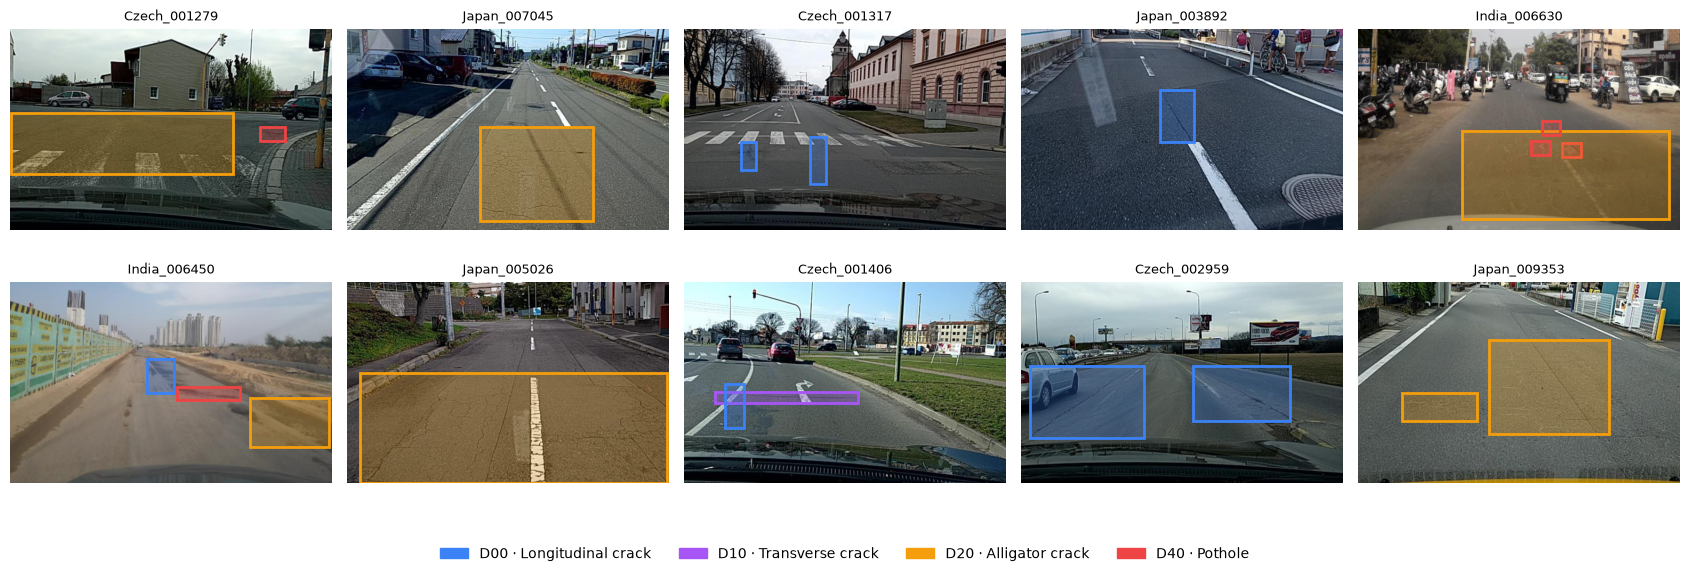

In [6]:
rng = np.random.default_rng(config.SEED)
ids = rng.choice(kept.image_id.unique(), size=10, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(17, 6))
for ax, iid in zip(axes.ravel(), ids):
    p = images.set_index("image_id").loc[iid, "path"]
    ax.imshow(crop_resize(Image.open(config.RAW / p).convert("RGB")))
    draw(ax, kept[kept.image_id == iid], ("xmin", "ymin", "xmax", "ymax"))
    ax.set_title(iid, fontsize=9)
    ax.axis("off")
fig.legend(handles=LEGEND, loc="lower center", ncol=4, frameon=False)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

In [7]:
# automatic checks on every kept box
assert (kept.xmin >= 0).all() and (kept.ymin >= 0).all(), "a box starts outside the image"
assert (kept.xmax <= config.IMG_W).all() and (kept.ymax <= config.IMG_H).all(), "a box ends outside the image"
assert ((kept.xmax > kept.xmin) & (kept.ymax > kept.ymin)).all(), "a box has no size"
print("all", len(kept), "boxes are inside the 640 x 400 image and have a size")

all 6112 boxes are inside the 640 x 400 image and have a size


### Result

| | Count |
|---|---|
| Boxes before | 6,228 |
| Dropped: entirely above the crop line | 116 |
| Kept, but clipped at the crop line | 213 |
| **Boxes after** | **6,112** |

| Class | D00 | D10 | D20 | D40 |
|---|---|---|---|---|
| Before | 1,951 | 1,082 | 1,836 | 1,359 |
| After | 1,932 | 1,045 | 1,817 | 1,318 |

- The crop costs 116 boxes (1.9%) and the top part of 213 more, in line with the EDA estimate of about 3% of box area. D10 loses the most (37 of 1,082, 3.4%).
- All 6,112 boxes lie inside the 640 × 400 image and have a size (checked in code), and in the 10-photo check the boxes stay on the same part of the road as in the original.
- The check by eye can only show that the boxes sit in the right place, not that a thin crack is visible inside one.

**To remember:** the app must use the same `crop_resize` (bottom 5/8, then 640 × 400 with `Image.BILINEAR`). A 540-px Japan photo doesn't divide evenly (337.5 rows), so the crop is rounded to 338 rows; the app must round the same way.

The moved boxes are saved as `data/processed/06_squares/boxes_640x400.csv` for 6.2 (cut into squares and label).

## 6.2 Cut into squares and label each one

Cut every 640 × 400 photo into 8 × 5 = 40 squares of 80 × 80 px, and give each square a label from the boxes that overlap it.

### Rules we fix before looking (and what they are based on)

| Rule | Value | Where it comes from | How we check it here |
|---|---|---|---|
| Grid | 8 columns × 5 rows of 80 × 80 px | **Assumption.** 80 px divides 640 × 400 exactly. Smaller squares give a finer map but more squares to process. | Not tested here |
| A square is labelled from **boxes**, not from pixels | The dataset only gives boxes | **Given by the dataset.** Boxes are loose, so some labelled squares will contain mostly clean road. | Look at the 10 photos below |
| A box labels a square if it covers **at least 10%** of it (640 of 6,400 px²) | 10% (first run: 15%) | **Assumption.** We started at 15% as a guess, not a number from the data. The test in section 3 showed 15% lost a quarter of the potholes, so we lowered it to 10% and re-ran (see Findings). EDA gave one warning sign: 13.7% of potholes are smaller than 15% of a square, so they can never label anything. Each box counts on its own; two small boxes of the same class are not added together. | **Tested in section 3**: the same labelling at 5%, 10%, 15% and 25% |
| If several classes qualify, the most serious wins: **pothole > alligator > transverse > longitudinal** | order | **Assumption** based on how urgent each repair is. It is our own judgement (the same order as the priority weights in the app), not a result from the data. | **Counted in section 3**: how many squares have a conflict |
| No box qualifies | label `none` | Follows from the rules above | Share of `none` should come out around 85–90% (our guess from the plan) |

If the tests show an assumption is wrong, we change it and re-run this notebook.

In [8]:
SQ = config.SQUARE                      # 80
COLS, ROWS = config.IMG_W // SQ, config.IMG_H // SQ   # 8 x 5
SEVERITY = ["D00", "D10", "D20", "D40"]  # least -> most serious; the last one wins a conflict
LABELS = SEVERITY + ["none"]

boxes = kept.reset_index(drop=True)  # from here on, `boxes` means the boxes moved in 6.1 (640 x 400)
print(len(images), "photos,", len(boxes), "boxes,", COLS, "x", ROWS, "=", COLS * ROWS, "squares per photo")

6000 photos, 6112 boxes, 8 x 5 = 40 squares per photo


### 1. How much of each square does each box cover?

For every box and each of the 40 squares: the overlap area (width of the overlap × its height, or 0), as a share of the square's 6,400 px².

In [9]:
sx0 = np.tile(np.arange(COLS) * SQ, ROWS)                 # left edge of each of the 40 squares (row by row)
sy0 = np.repeat(np.arange(ROWS) * SQ, COLS)               # top edge

ow = np.clip(np.minimum(boxes.xmax.values[:, None], sx0 + SQ) - np.maximum(boxes.xmin.values[:, None], sx0), 0, None)
oh = np.clip(np.minimum(boxes.ymax.values[:, None], sy0 + SQ) - np.maximum(boxes.ymin.values[:, None], sy0), 0, None)
cover = ow * oh / (SQ * SQ)        # shape: (boxes, 40), 0 = no overlap, 1 = box covers the whole square
print("cover table:", cover.shape)

# example: the first box of a damaged photo
i = 0
print(boxes.iloc[i][["image_id", "cls", "xmin", "ymin", "xmax", "ymax"]].to_dict())
print("squares it touches (index: share of the square covered):", {int(s): round(float(cover[i, s]), 2) for s in np.nonzero(cover[i])[0]})

cover table: (6112, 40)
{'image_id': 'Czech_000006', 'cls': 'D00', 'xmin': 150.4, 'ymin': 192.0, 'xmax': 177.1, 'ymax': 263.5}
squares it touches (index: share of the square covered): {17: 0.07, 18: 0.13, 25: 0.04, 26: 0.06}


### 2. Label every square

In [10]:
img_index = {iid: n for n, iid in enumerate(images.image_id)}
box_img = boxes.image_id.map(img_index).values
box_cls = boxes.cls.map(SEVERITY.index).values


def label_squares(threshold):
    """Return (labels, conflicts): labels is (photos, 40) with 0-3 = class, 4 = none."""
    qualifies = cover >= threshold
    has = np.zeros((len(images), COLS * ROWS, 4), dtype=bool)
    for k in range(4):
        sel = box_cls == k
        np.logical_or.at(has[:, :, k], box_img[sel], qualifies[sel])
    labels = np.full((len(images), COLS * ROWS), 4)
    for k in range(4):                 # least serious first, so a more serious class overwrites it
        labels[has[:, :, k]] = k
    return labels, has.sum(axis=2) >= 2


labels, conflict = label_squares(config.LABEL_MIN_OVERLAP)
print("labelled squares:", labels.size)

labelled squares: 240000


### 3. Test the assumptions: what happens at other thresholds?

In [11]:
rows = []
for t in [0.05, 0.10, 0.15, 0.25]:
    lab, conf = label_squares(t)
    unlabelled = cover.max(axis=1) < t
    rows.append({
        "threshold": f"{t:.0%}",
        "damage squares": f"{(lab < 4).mean():.1%}",
        "none squares": f"{(lab == 4).mean():.1%}",
        "boxes that label no square": int(unlabelled.sum()),
        "...of which potholes": int((unlabelled & (box_cls == 3)).sum()),
        "squares with 2+ classes": int(conf.sum()),
    })
pd.DataFrame(rows).set_index("threshold")

,damage squares,none squares,boxes that label no square,...of which potholes,squares with 2+ classes
threshold,,,,,
5%,12.9%,87.1%,40,23,2097
10%,11.9%,88.1%,251,155,1672
15%,11.1%,88.9%,546,312,1347
25%,9.6%,90.4%,1345,589,900


In [12]:
counts = pd.Series(labels.ravel()).map(dict(enumerate(LABELS))).value_counts().reindex(LABELS)
print(f"at {config.LABEL_MIN_OVERLAP:.0%}: {counts['none'] / counts.sum():.1%} of squares are none")
pd.DataFrame({"squares": counts, "share": (counts / counts.sum()).round(3)})

at 10%: 88.1% of squares are none


,squares,share
D00,4764,0.020
D10,2495,0.010
D20,18460,0.077
D40,2903,0.012
none,211378,0.881


In [13]:
# conflicts at the chosen threshold: which classes fight over a square, and who wins?
has_cls = np.zeros((len(images), COLS * ROWS, 4), dtype=bool)
q = cover >= config.LABEL_MIN_OVERLAP
for k in range(4):
    sel = box_cls == k
    np.logical_or.at(has_cls[:, :, k], box_img[sel], q[sel])
pairs = {}
for a in range(4):
    for b_ in range(a + 1, 4):
        pairs[f"{SEVERITY[b_]} beats {SEVERITY[a]}"] = int((has_cls[:, :, a] & has_cls[:, :, b_]).sum())
print("squares where two classes both qualify, and which one the severity rule picks:")
pd.Series(pairs).rename("squares")

squares where two classes both qualify, and which one the severity rule picks:


D10 beats D00    263
D20 beats D00    514
D40 beats D00     88
D20 beats D10    270
D40 beats D10     20
D40 beats D20    579
Name: squares, dtype: int64

### 4. Save `patches.csv`

In [14]:
n_img = len(images)
patches = pd.DataFrame({
    "image_id": np.repeat(images.image_id.values, COLS * ROWS),
    "country": np.repeat(images.country.values, COLS * ROWS),
    "row": np.tile(np.repeat(np.arange(ROWS), COLS), n_img),
    "col": np.tile(np.tile(np.arange(COLS), ROWS), n_img),
    "label": pd.Series(labels.ravel()).map(dict(enumerate(LABELS))).values,
})
patches.insert(0, "patch_id", patches.image_id + "_r" + patches.row.astype(str) + "_c" + patches.col.astype(str))

assert len(patches) == len(images) * 40, "rows must be photos x 40"
assert patches.patch_id.is_unique
out = config.PROCESSED / "06_squares"
patches.to_csv(out / "patches.csv", index=False)
print(len(patches), "rows =", len(images), "photos x 40. Saved", out / "patches.csv")
patches.head()

240000 rows = 6000 photos x 40. Saved /Users/user/Documents/Y4/ML/road-damage-classifier/backend/data/processed/06_squares/patches.csv


,patch_id,image_id,country,row,col,label
0,Czech_000000_r0_c0,Czech_000000,Czech,0,0,none
1,Czech_000000_r0_c1,Czech_000000,Czech,0,1,none
2,Czech_000000_r0_c2,Czech_000000,Czech,0,2,none
3,Czech_000000_r0_c3,Czech_000000,Czech,0,3,none
4,Czech_000000_r0_c4,Czech_000000,Czech,0,4,none


### 5. Check: label colours on 10 random photos

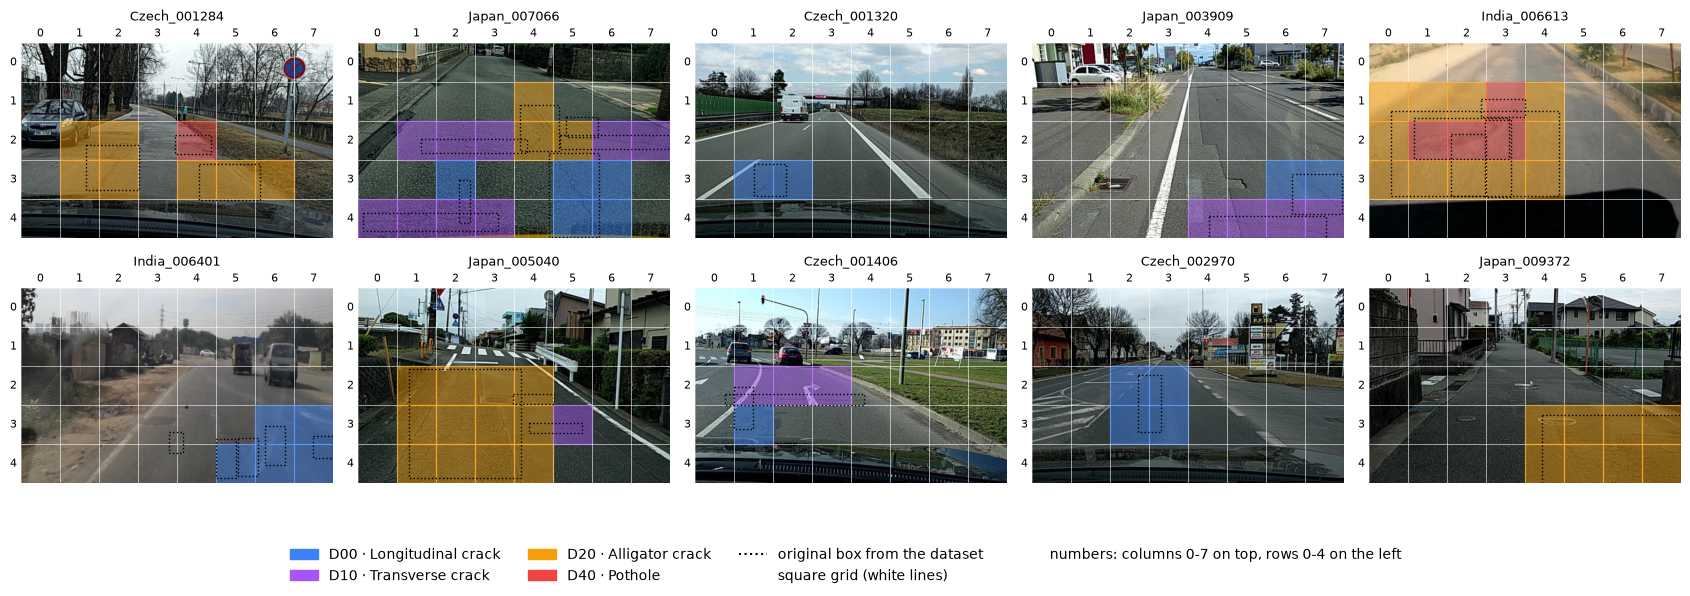

In [15]:
rng = np.random.default_rng(config.SEED)
with_damage = images.image_id.values[(labels < 4).any(axis=1)]
ids = rng.choice(with_damage, size=10, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(17, 6))
for ax, iid in zip(axes.ravel(), ids):
    ax.imshow(crop_resize(Image.open(config.RAW / images.set_index("image_id").loc[iid, "path"]).convert("RGB")))
    for s in range(COLS * ROWS):
        x, y = sx0[s], sy0[s]
        ax.add_patch(Rectangle((x, y), SQ, SQ, fill=False, edgecolor="white", linewidth=0.4, alpha=0.6))
        lab = labels[img_index[iid], s]
        if lab < 4:
            ax.add_patch(Rectangle((x, y), SQ, SQ, color=COLORS[lab], alpha=0.45))
    for r in boxes[boxes.image_id == iid].itertuples():      # the original box outlines, thin
        ax.add_patch(Rectangle((r.xmin, r.ymin), r.xmax - r.xmin, r.ymax - r.ymin, fill=False, edgecolor="black", linewidth=1, linestyle=":"))
    for col in range(COLS):                                   # column numbers along the top
        ax.text(col * SQ + SQ / 2, -8, str(col), ha="center", va="bottom", fontsize=8)
    for row in range(ROWS):                                   # row numbers down the left
        ax.text(-8, row * SQ + SQ / 2, str(row), ha="right", va="center", fontsize=8)
    ax.set_title(iid, fontsize=9, pad=16)
    ax.axis("off")
from matplotlib.lines import Line2D
extra = [Line2D([0], [0], color="black", linestyle=":", label="original box from the dataset"),
         Line2D([0], [0], color="white", linewidth=1, label="square grid (white lines)"),
         Line2D([0], [0], color="none", label="numbers: columns 0-7 on top, rows 0-4 on the left")]
fig.legend(handles=LEGEND + extra, loc="lower center", ncol=4, frameon=False)
plt.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

### 6. Save each square as a PNG (optional)

Every square becomes an 80 × 80 PNG in a folder named after its label, so you can open a folder and flick through what, for example, a "pothole" square looks like:

```
data/processed/06_squares/patches/
  D00/  D10/  D20/  D40/  none/      file name = patch_id, e.g. Japan_012660_r3_c5.png
```

The folder is emptied first, so after a threshold change it never keeps squares with an old label. About 2 GB, a couple of minutes.

In [16]:
import shutil

from tqdm.auto import tqdm

OUT = config.PROCESSED / "06_squares" / "patches"
shutil.rmtree(OUT, ignore_errors=True)
for lab in LABELS:
    (OUT / lab).mkdir(parents=True)

label_of = patches.set_index("patch_id").label
for _, info in tqdm(images.iterrows(), total=len(images), desc="photos"):
    frame = crop_resize(Image.open(config.RAW / info.path).convert("RGB"))   # 640 x 400, same as 6.1
    for row in range(ROWS):
        for col in range(COLS):
            pid = f"{info.image_id}_r{row}_c{col}"
            square = frame.crop((col * SQ, row * SQ, (col + 1) * SQ, (row + 1) * SQ))
            square.save(OUT / label_of[pid] / f"{pid}.png")

saved = {lab: len(list((OUT / lab).glob("*.png"))) for lab in LABELS}
print(saved, "total", sum(saved.values()))
assert saved == patches.label.value_counts().to_dict(), "PNG count per folder should match patches.csv"

photos:   0%|          | 0/6000 [00:00<?, ?it/s]

{'D00': 4764, 'D10': 2495, 'D20': 18460, 'D40': 2903, 'none': 211378} total 240000


**Check:** 8 random PNGs from each folder, read back from disk. Each row should look like its class: lines along the road for D00, across it for D10, a net of cracks for D20, dark holes for D40, and plain road for `none`. Some will look clean, because boxes are loose (see the rules table).

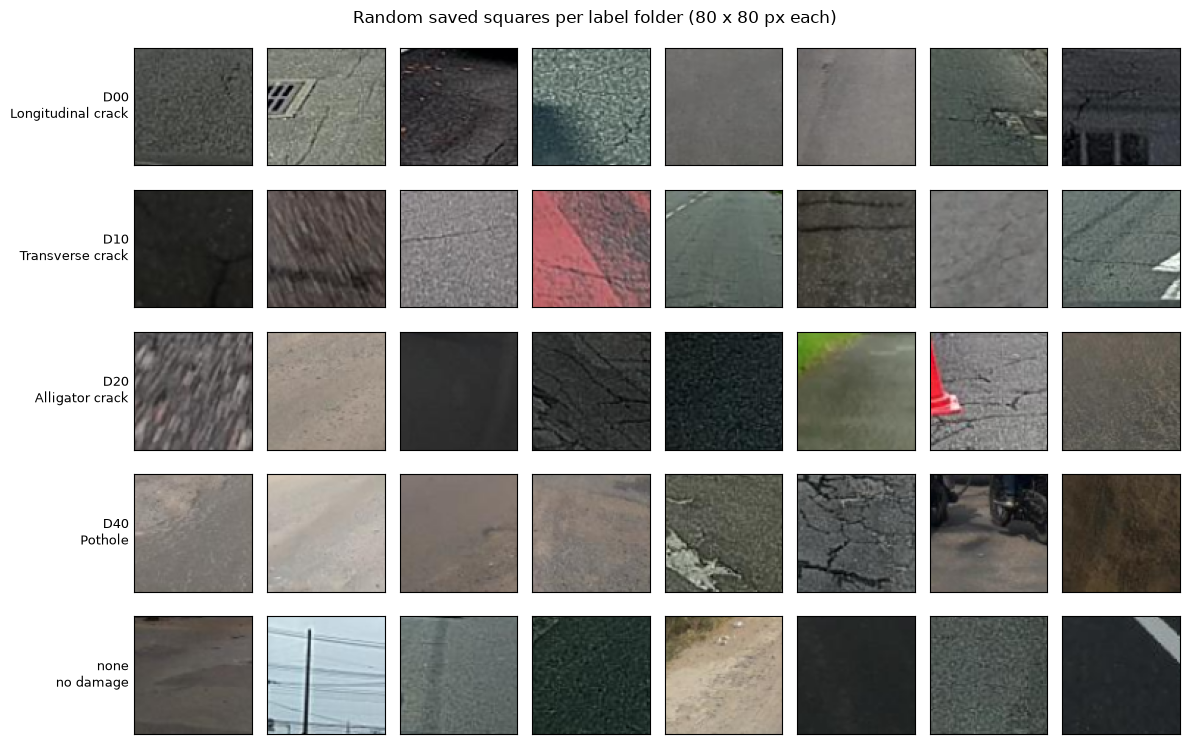

In [17]:
rng = np.random.default_rng(config.SEED)
fig, axes = plt.subplots(len(LABELS), 8, figsize=(12, 7.6))
for r, lab in enumerate(LABELS):
    files = sorted((OUT / lab).glob("*.png"))
    for ax, f in zip(axes[r], rng.choice(files, size=8, replace=False)):
        ax.imshow(Image.open(f))
        ax.set_xticks([]); ax.set_yticks([])
    axes[r, 0].set_ylabel(NAMES.get(lab, "none · no damage").replace(" · ", "\n"), rotation=0, ha="right", va="center", fontsize=9)
plt.suptitle("Random saved squares per label folder (80 x 80 px each)")
plt.tight_layout()
plt.show()

### Findings: did the assumptions hold?

#### First run, at 15% (the starting assumption)

**Result:** 88.9% none, D20 7.4%, D00 1.8%, D40 1.0%, D10 0.9%. The "about 85–90% none" guess was right, but the threshold test (section 3) showed a real cost:

| Threshold | Damage squares | Boxes that label no square | ...of which potholes |
|---|---|---|---|
| 5% | 12.9% | 40 | 23 |
| 10% | 11.9% | 251 | 155 |
| **15%** | **11.1%** | **546 (8.9% of boxes)** | **312 (24% of the potholes)** |
| 25% | 9.6% | 1,345 | 589 |

- At 15%, almost **a quarter of the potholes never labelled a square**. That is more than the 13.7% the EDA predicted, because the EDA only counted boxes smaller than 15% of a square. A box that is bigger but split over several squares can also miss 15% in every one of them.
- **Pothole suffered most**, and it is the class we care about most: only 2,490 D40 squares (1.0%).
- Lower thresholds save potholes but also colour squares that are mostly clean road, because boxes are loose. The data can't pick the value; it only shows the trade-off.

#### Decision: lower to 10% and re-run

10% halves the lost potholes (312 → 155) while the damage share only rises from 11.1% to 11.9%, so little clean road gets labelled. 5% would save even more potholes, but a box would then label any square it barely touches. Changed in one place: `LABEL_MIN_OVERLAP = 0.10` in `ml/config.py`.

#### Final run, at 10% (what `patches.csv` now uses)

**Result:** 240,000 squares (6,000 photos × 40), saved as `data/processed/06_squares/patches.csv`. **88.1% none**, D20 7.7%, D00 2.0%, D40 1.2%, D10 1.0%. Still inside the expected 85–90% none.

- **D40 squares: 2,490 → 2,903** (+17%). 155 pothole boxes (12%) still label nothing; these are the very small or very thin ones.
- In the 10-photo check above, compare dotted boxes with no colour: there are fewer than at 15%.

**The severity order (assumption):** 1,672 squares (about 6% of the damage squares) have a conflict. The most common are still **a pothole inside an alligator crack** (579 squares) and **an alligator crack over a longitudinal crack** (514). So the order matters mostly for D40 vs D20, and "pothole wins" keeps the potholes that would otherwise be hidden by the larger crack area.

**PNGs (section 6):** all 240,000 squares saved as 80 × 80 PNGs in `data/processed/06_squares/patches/<label>/`, one folder per label, with the counts matching `patches.csv`. Flicking through them (section 6 figure) shows the cost of box labels: many D00/D10/D20/D40 squares look like clean road, and some D40 squares show cracks instead of a hole, because the box around the damage is bigger than the damage. A few `none` squares still show sky or poles, from photos where the horizon is lower than 3/8. These are label noise the models will have to live with, not bugs.